In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score

In [2]:
df = pd.read_csv('../data/telco_churn.csv')

In [3]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df.dropna(inplace=True)
df.drop('customerID', axis=1, inplace=True)

In [4]:
le = LabelEncoder()
for col in df.select_dtypes('object').columns:
    df[col] = le.fit_transform(df[col])

print("Данные готовы:", df.shape)
df.head()

Данные готовы: (7032, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,1,0,0,2,0,0,0,0,0,1,2,29.85,29.85,0
1,1,0,0,0,34,1,0,0,2,0,2,0,0,0,1,0,3,56.95,1889.50,0
2,1,0,0,0,2,1,0,0,2,2,0,0,0,0,0,1,3,53.85,108.15,1
3,1,0,0,0,45,0,1,0,2,0,2,2,0,0,1,0,0,42.30,1840.75,0
4,0,0,0,0,2,1,0,1,0,0,0,0,0,0,0,1,2,70.70,151.65,1


In [5]:
X = df.drop('Churn', axis=1)
y = df['Churn']

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Train размер:", X_train.shape)
print("Test размер:", X_test.shape)

Train размер: (5625, 19)
Test размер: (1407, 19)


In [6]:
lr = LogisticRegression(random_state=42, max_iter=1000)
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)
lr_auc = roc_auc_score(y_test, lr.predict_proba(X_test)[:,1])

print("=== Logistic Regression ===")
print(classification_report(y_test, lr_pred))
print(f"ROC-AUC: {lr_auc:.3f}")

=== Logistic Regression ===
              precision    recall  f1-score   support

           0       0.85      0.88      0.86      1033
           1       0.62      0.56      0.59       374

    accuracy                           0.79      1407
   macro avg       0.74      0.72      0.73      1407
weighted avg       0.79      0.79      0.79      1407

ROC-AUC: 0.835


In [7]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
rf_auc = roc_auc_score(y_test, rf.predict_proba(X_test)[:,1])

print("=== Random Forest ===")
print(classification_report(y_test, rf_pred))
print(f"ROC-AUC: {rf_auc:.3f}")

=== Random Forest ===
              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1033
           1       0.62      0.48      0.54       374

    accuracy                           0.78      1407
   macro avg       0.72      0.69      0.70      1407
weighted avg       0.77      0.78      0.77      1407

ROC-AUC: 0.811


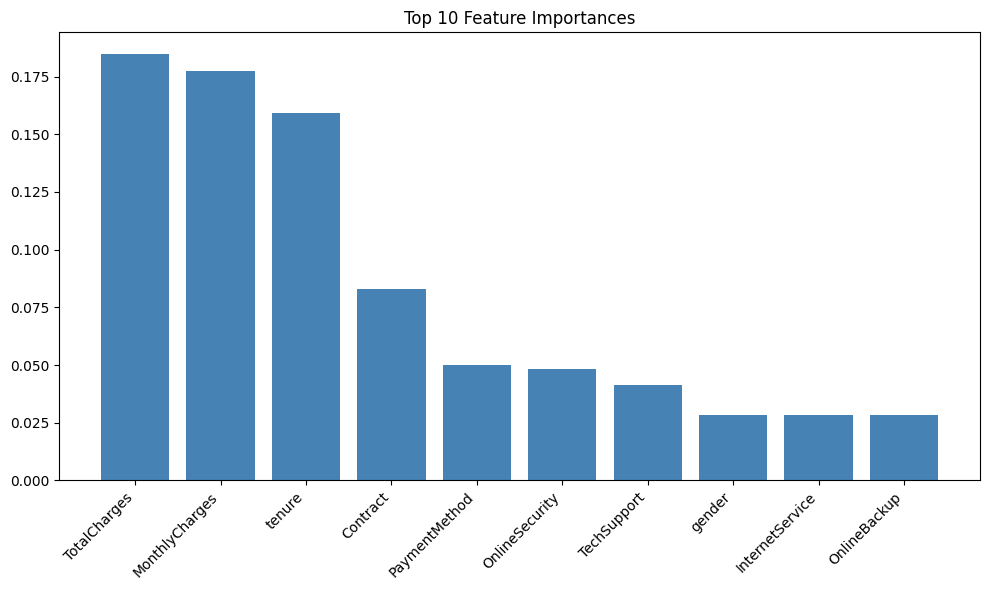

In [8]:
import matplotlib.pyplot as plt

feature_names = df.drop('Churn', axis=1).columns
importances = rf.feature_importances_

indices = np.argsort(importances)[::-1][:10]

plt.figure(figsize=(10, 6))
plt.bar(range(10), importances[indices], color='steelblue')
plt.xticks(range(10), feature_names[indices], rotation=45, ha='right')
plt.title('Top 10 Feature Importances')
plt.tight_layout()
plt.savefig('../data/feature_importance.png')
plt.show()

In [9]:
import mlflow
import mlflow.sklearn

mlflow.set_experiment("churn-prediction")

with mlflow.start_run(run_name="logistic_regression"):
    mlflow.log_param("model", "LogisticRegression")
    mlflow.log_param("max_iter", 1000)
    mlflow.log_metric("accuracy", 0.79)
    mlflow.log_metric("roc_auc", 0.835)
    mlflow.sklearn.log_model(lr, "model")

with mlflow.start_run(run_name="random_forest"):
    mlflow.log_param("model", "RandomForest")
    mlflow.log_param("n_estimators", 100)
    mlflow.log_metric("accuracy", 0.78)
    mlflow.log_metric("roc_auc", 0.811)
    mlflow.sklearn.log_model(rf, "model")

print("Эксперименты залогированы!")

2026/03/18 14:50:57 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/03/18 14:50:57 INFO mlflow.store.db.utils: Updating database tables
2026/03/18 14:50:59 INFO mlflow.tracking.fluent: Experiment with name 'churn-prediction' does not exist. Creating a new experiment.
2026/03/18 14:50:59 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git SHA is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w

Эксперименты залогированы!


In [11]:
import pickle

with open("../model.pkl", "wb") as f:
    pickle.dump(lr, f)

print("Модель сохранена!")

Модель сохранена!
